# Facebook Prophet Model 

Facebook Prophet Prophet is a procedure for forecasting time series data based on an additive model where 
non-linear trends are fit with yearly, weekly, and daily seasonality, plus holiday effects.
It works best with time series that have strong seasonal effects and several seasons of historical data. 
Prophet is robust to shifts in the trend, and typically handles outliers well.

## Non-Linear Trends in Time Series Forecasting

A **trend** represents the long-term progression of a time series. While a **linear trend** increases or decreases at a **constant rate**, a **non-linear trend** changes its rate of growth or decay over time.

**ARIMA models treat trend as a problem to remove, not as a component to explain.** <br>
**ARIMA does not model changepoints**

# 📈 Non-Linear Trends in Time Series Forecasting

A **trend** represents the long-term progression of a time series. While a **linear trend** increases or decreases at a **constant rate**, 
a **non-linear trend** changes its rate of growth or decay over time.

## Examples of Non-Linear Trend Models

### 1. Quadratic / Polynomial Trend

Captures acceleration or deceleration in the trend.

$$
y_t = \alpha + \beta_1 t + \beta_2 t^2
$$

- If \( \beta_2 > 0 \): upward curve  
- If \( \beta_2 < 0 \): downward curve  
- Used in macroeconomic growth, learning curves

### 2. Exponential Growth

$$
y_t = ae^{bt}
$$

- \( b > 0 \): exponential growth  
- \( b < 0 \): exponential decay  
- Used for modeling populations, pandemics, viral content

### 3. Logistic Growth (S-shaped) #Rapid rise then plateau 

$$
y_t = \frac{C}{1 + e^{-k(t - m)}}
$$

- Starts slowly, grows rapidly, and then **flattens**  
- \( C \): carrying capacity (maximum value)  
- Used in technology adoption, diffusion of innovations, and saturation modeling

### 4. Piecewise Linear Trend (Used in Facebook Prophet) #This allows Prophet to detect structural breaks

Breaks the trend into segments, each with a different slope:

$$
g(t) = \left(k + \mathbf{a}(t)^\top \delta \right) t + \left(m + \mathbf{a}(t)^\top \gamma \right)
$$

- Prophet uses this to detect **changepoints** automatically  
- Allows for **non-linear global behavior**, even though each segment is linear

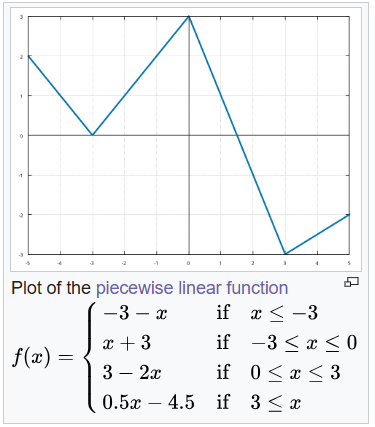

## Model Decomposition

Prophet models a univariate time series \( y(t) \) using an **additive model**:

$$
y(t) = g(t) + s(t) + h(t) + \varepsilon_t
$$

Where:
- \( g(t) \): **Trend function** (Piecewise Linear Trend  & Logistic Growth Trend)
- \( s(t) \): **Seasonality** component (e.g., weekly, yearly)
- \( h(t) \): **Holiday effects**, capturing irregular events
- \( \varepsilon_t \): **Error term**, assumed to be normally distributed

## 📦 Features of Prophet

- **Automatic changepoint detection** for structural breaks
- Handles **outliers** robustly
- Accepts **external regressors**
- Provides **forecast uncertainty intervals**
- Designed for **daily or higher-frequency data**

---

#### Forecasting Using FbProphet

In [ ]:
#!python -m pip install prophet

In [1]:
import pandas as pd
from prophet import Prophet
import matplotlib.pyplot as plt
%matplotlib inline

C:\Users\Brahim\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
url = "https://raw.githubusercontent.com/brahzr/Time-series-Analysis/refs/heads/main/airline_passengers.csv"
df=pd.read_csv(url)

In [4]:
df.head()

,Month,Thousands of Passengers
0,1949-01,112.0
1,1949-02,118.0
2,1949-03,132.0
3,1949-04,129.0
4,1949-05,121.0


In [ ]:
df.tail()

In [ ]:
df.plot()

In [ ]:
df.columns = ['ds','y']
df.head()

In [ ]:
#df.dropna(df[""]) axis = 0 rows, axis = 1 columns

In [ ]:
df.drop(144,axis=0,inplace=True)

In [ ]:
df.tail()

In [ ]:
df.info()

In [ ]:
df['ds'] = pd.to_datetime(df['ds'])

In [ ]:
df.info()

In [ ]:
df.head()

In [ ]:
dir(Prophet)

In [ ]:
# Initialize the Model
model = Prophet() 

In [ ]:
model.fit(df)

---

In [ ]:
### Create future dates of 365 days
future_dates = model.make_future_dataframe(periods=365)

In [ ]:
future_dates.tail()

In [ ]:
prediction = model.predict(future_dates)

In [ ]:
prediction[['ds','yhat','yhat_lower', 'yhat_upper']].tail(100)

In [ ]:
### plot the predicted projection
model.plot(prediction)
#Black points: observed values from your original data
#Blue Line: the forecast (yhat) from the model.
#Shaded Area: the uncertainty interval, defined by: yhat_lower & yhat_upper

In [ ]:
#### Visualize Each Components[Trends,yearly]
model.plot_components(prediction)

In [ ]:
#Detect changepoints
from prophet.plot import add_changepoints_to_plot
fig = model.plot(prediction)
a = add_changepoints_to_plot(fig.gca(), model, prediction)

**Acuracy and Performance**

Train on 2 years → predict 1 year → check accuracy  
Shift 6 months → train again → predict next year → check again  
... repeat

In [ ]:
from prophet.diagnostics import cross_validation

01/01/1949----01/12/1960: 19(6months)
01/01/1949---01/01/1951
6months-----1 years
6months-----1 year

In [ ]:
df_cv = cross_validation(model,
    initial='730 days',   #2 years for training  
    period='180 days',    #6 months for training each time
    horizon='365 days')   #predict 1 year

In [ ]:
df_cv
df_cv.to_csv("cross vald.csv")

In [ ]:
df_cv.head(50)

In [ ]:
from prophet.diagnostics import performance_metrics
df_metrics = performance_metrics(df_cv)
df_metrics.head()

In [ ]:
import matplotlib.pyplot as plt

# 1. Plot the 'mape' column straight from your metrics table
plt.plot(df_metrics['horizon'].dt.days, df_metrics['mape'], color='blue')

# 2. Add simple labels so it looks nice
plt.xlabel('Days into the Future (Horizon)')
plt.ylabel('MAPE (Error Percentage)')
plt.title('Prediction Error Over Time')
plt.show()
